In [1]:
import os, json
import numpy as np
from pathlib import Path

# ── Path to your fusion preprocessed dataset ──────────────────────────
BASE = "/kaggle/input/datasets/jarinproma/pgcn-deap-fusion-preprocessed/preprocessed_fusion"

# 22 subjects with genuine facial video
FUSION_SUBJECTS = [f"s{i:02d}" for i in range(1, 23)]

embeddings = []   # ViT embedding per trial
labels_subj = []  # subject identity label (0-21)
labels_emot = []  # quadrant label (0-3) for comparison
has_video   = []  # whether this subject has real video

for idx, subj in enumerate(FUSION_SUBJECTS):
    subj_dir = f"{BASE}/{subj}"
    meta_path = f"{subj_dir}/meta.json"
    
    if not os.path.exists(meta_path):
        print(f"  ✗ Missing: {subj}")
        continue
    
    meta = json.load(open(meta_path))
    real_video = meta.get("has_real_video", False)
    
    # Load trial-level video embeddings
    # Try common file names used in preprocessing
    for fname in ["video_embeddings.npy", "vid_embeddings.npy", "embeddings.npy"]:
        emb_path = f"{subj_dir}/{fname}"
        if os.path.exists(emb_path):
            emb = np.load(emb_path)  # shape: (40, 768) — one per trial
            embeddings.append(emb)
            labels_subj.extend([idx] * len(emb))
            has_video.extend([real_video] * len(emb))
            print(f"  ✔ {subj}: {emb.shape}  real_video={real_video}")
            break
    else:
        # Check what files are in the directory
        files = os.listdir(subj_dir)
        npy_files = [f for f in files if f.endswith('.npy')]
        print(f"  ? {subj}: no embedding file found. npy files: {npy_files}")

X = np.vstack(embeddings)           # (22×40, 768) = (880, 768)
y = np.array(labels_subj)           # (880,) — subject identity

print(f"\nDataset shape : {X.shape}")
print(f"Subjects      : {len(np.unique(y))}")
print(f"Trials/subject: {len(X) // len(np.unique(y))}")
print(f"Chance level  : {1/len(np.unique(y))*100:.1f}%")

  ? s01: no embedding file found. npy files: ['norm_std.npy', 'norm_mean.npy']
  ? s02: no embedding file found. npy files: ['norm_std.npy', 'norm_mean.npy']
  ? s03: no embedding file found. npy files: ['norm_std.npy', 'norm_mean.npy']
  ? s04: no embedding file found. npy files: ['norm_std.npy', 'norm_mean.npy']
  ? s05: no embedding file found. npy files: ['norm_std.npy', 'norm_mean.npy']
  ? s06: no embedding file found. npy files: ['norm_std.npy', 'norm_mean.npy']
  ? s07: no embedding file found. npy files: ['norm_std.npy', 'norm_mean.npy']
  ? s08: no embedding file found. npy files: ['norm_std.npy', 'norm_mean.npy']
  ? s09: no embedding file found. npy files: ['norm_std.npy', 'norm_mean.npy']
  ? s10: no embedding file found. npy files: ['norm_std.npy', 'norm_mean.npy']
  ? s11: no embedding file found. npy files: ['norm_std.npy', 'norm_mean.npy']
  ? s12: no embedding file found. npy files: ['norm_std.npy', 'norm_mean.npy']
  ? s13: no embedding file found. npy files: ['norm_

ValueError: need at least one array to concatenate

In [3]:
import os

BASE = "/kaggle/input/datasets/jarinproma/pgcn-deap-fusion-preprocessed/preprocessed_fusion"

subj = "s01"
print(f"Files in {subj}:")
for f in sorted(os.listdir(f"{BASE}/{subj}")):
    fpath = f"{BASE}/{subj}/{f}"
    size = os.path.getsize(fpath)
    if f.endswith('.npy'):
        arr = np.load(fpath)
        print(f"  {f:40s}  shape={arr.shape}  dtype={arr.dtype}")
    else:
        print(f"  {f:40s}  size={size} bytes")

Files in s01:
  meta.json                                 size=1245 bytes
  norm_mean.npy                             shape=(1, 21)  dtype=float32
  norm_std.npy                              shape=(1, 21)  dtype=float32
  trial_00                                  size=0 bytes
  trial_01                                  size=0 bytes
  trial_02                                  size=0 bytes
  trial_03                                  size=0 bytes
  trial_04                                  size=0 bytes
  trial_05                                  size=0 bytes
  trial_06                                  size=0 bytes
  trial_07                                  size=0 bytes
  trial_08                                  size=0 bytes
  trial_09                                  size=0 bytes
  trial_10                                  size=0 bytes
  trial_11                                  size=0 bytes
  trial_12                                  size=0 bytes
  trial_13                             

In [4]:
import os, numpy as np

BASE = "/kaggle/input/datasets/jarinproma/pgcn-deap-fusion-preprocessed/preprocessed_fusion"

# Look inside trial_00 of s01
trial_path = f"{BASE}/s01/trial_00"
print(f"Is directory: {os.path.isdir(trial_path)}")
print(f"Contents of trial_00:")
for f in sorted(os.listdir(trial_path)):
    fpath = f"{trial_path}/{f}"
    if f.endswith('.npy'):
        arr = np.load(fpath)
        print(f"  {f:40s}  shape={arr.shape}  dtype={arr.dtype}")
    else:
        print(f"  {f:40s}  size={os.path.getsize(fpath)} bytes")

Is directory: True
Contents of trial_00:
  win_00.pt                                 size=19396 bytes
  win_01.pt                                 size=19396 bytes
  win_02.pt                                 size=19396 bytes
  win_03.pt                                 size=19396 bytes
  win_04.pt                                 size=19396 bytes
  win_05.pt                                 size=19396 bytes
  win_06.pt                                 size=19396 bytes
  win_07.pt                                 size=19396 bytes
  win_08.pt                                 size=19396 bytes
  win_09.pt                                 size=19396 bytes
  win_10.pt                                 size=19396 bytes
  win_11.pt                                 size=19396 bytes
  win_12.pt                                 size=19396 bytes
  win_13.pt                                 size=19396 bytes
  win_14.pt                                 size=19396 bytes
  win_15.pt                                 

In [8]:
!pip show torch-geometric

In [9]:
!pip install -q torch-geometric

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.4/64.4 kB 1.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 20.4 MB/s eta 0:00:00a 0:00:01


In [10]:
from torch_geometric.data import Data

In [11]:
import torch
from torch_geometric.data import Data

# Load with weights_only=False since these are PyG Data objects
sample = torch.load(f"{BASE}/s01/trial_00/win_00.pt",
                    map_location='cpu', weights_only=False)

print(type(sample))
print(f"Keys: {sample.keys()}")
for key in sample.keys():
    val = getattr(sample, key)
    if hasattr(val, 'shape'):
        print(f"  {key:30s}: shape={val.shape}  dtype={val.dtype}")
    else:
        print(f"  {key:30s}: {val}")

<class 'torch_geometric.data.data.Data'>
Keys: ['window_idx', 'edge_weight_func', 'split', 'video', 'edge_index_struct', 'subject', 'edge_index_func', 'y', 'trial_idx', 'x', 'edge_weight_struct']
  window_idx                    : 0
  edge_weight_func              : shape=torch.Size([384])  dtype=torch.float32
  split                         : train
  video                         : shape=torch.Size([1, 768])  dtype=torch.float32
  edge_index_struct             : shape=torch.Size([2, 140])  dtype=torch.int64
  subject                       : s01
  edge_index_func               : shape=torch.Size([2, 384])  dtype=torch.int64
  y                             : shape=torch.Size([1, 5])  dtype=torch.int64
  trial_idx                     : 0
  x                             : shape=torch.Size([32, 21])  dtype=torch.float32
  edge_weight_struct            : shape=torch.Size([140])  dtype=torch.float32


In [12]:
import os, json, torch
import numpy as np
from torch_geometric.data import Data

BASE = "/kaggle/input/datasets/jarinproma/pgcn-deap-fusion-preprocessed/preprocessed_fusion"
FUSION_SUBJECTS = [f"s{i:02d}" for i in range(1, 23)]

embeddings  = []
labels_subj = []

for idx, subj in enumerate(FUSION_SUBJECTS):
    subj_dir = f"{BASE}/{subj}"
    meta = json.load(open(f"{subj_dir}/meta.json"))
    real_video = meta.get("has_real_video", False)

    subj_embs = []
    for trial_idx in range(40):
        trial_dir = f"{subj_dir}/trial_{trial_idx:02d}"
        win_path  = f"{trial_dir}/win_00.pt"
        if not os.path.exists(win_path):
            continue

        # Load PyG Data object
        data = torch.load(win_path, map_location='cpu', weights_only=False)

        # Print keys from first trial of first subject so we can see structure
        if idx == 0 and trial_idx == 0:
            print(f"PyG Data keys: {data.keys()}")
            for key in data.keys():
                val = getattr(data, key)
                if hasattr(val, 'shape'):
                    print(f"  {key:30s}: shape={val.shape}")
                else:
                    print(f"  {key:30s}: {val}")

        # ViT embedding is trial-level — same for all windows
        # Try common attribute names — update after seeing keys above
        emb = None
        for key in ["vid_emb", "video_emb", "vit_emb", "face_emb",
                    "video", "vid", "visual", "emb_vid", "vid_feat"]:
            if hasattr(data, key):
                emb = getattr(data, key).float().numpy().flatten()
                break

        if emb is not None:
            subj_embs.append(emb)

    if subj_embs:
        embeddings.extend(subj_embs)
        labels_subj.extend([idx] * len(subj_embs))
        print(f"  ✔ {subj}: {len(subj_embs)} trials  "
              f"emb_dim={len(subj_embs[0])}  real_video={real_video}")
    else:
        print(f"  ✗ {subj}: no ViT embedding attribute found")

if embeddings:
    X = np.array(embeddings)
    y = np.array(labels_subj)
    print(f"\nDataset : {X.shape}")
    print(f"Subjects: {len(np.unique(y))}")
    print(f"Chance  : {1/len(np.unique(y))*100:.1f}%")
else:
    print("\nNo embeddings loaded — check the key names printed above and update the loop")

PyG Data keys: ['window_idx', 'edge_weight_func', 'split', 'video', 'edge_index_struct', 'subject', 'edge_index_func', 'y', 'trial_idx', 'x', 'edge_weight_struct']
  window_idx                    : 0
  edge_weight_func              : shape=torch.Size([384])
  split                         : train
  video                         : shape=torch.Size([1, 768])
  edge_index_struct             : shape=torch.Size([2, 140])
  subject                       : s01
  edge_index_func               : shape=torch.Size([2, 384])
  y                             : shape=torch.Size([1, 5])
  trial_idx                     : 0
  x                             : shape=torch.Size([32, 21])
  edge_weight_struct            : shape=torch.Size([140])
  ✔ s01: 40 trials  emb_dim=768  real_video=True
  ✔ s02: 40 trials  emb_dim=768  real_video=True
  ✔ s03: 40 trials  emb_dim=768  real_video=True
  ✔ s04: 40 trials  emb_dim=768  real_video=True
  ✔ s05: 40 trials  emb_dim=768  real_video=True
  ✔ s06: 40 trials  em

In [13]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedKFold, cross_val_score, LeaveOneGroupOut
import numpy as np

print("="*60)
print("  EXPERIMENT: Can ViT embeddings identify subjects?")
print("="*60)
print(f"  Dataset     : {X.shape}")
print(f"  Subjects    : {len(np.unique(y))}")
print(f"  Chance level: {1/len(np.unique(y))*100:.1f}%")

# ── Standardise ───────────────────────────────────────────────
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# ── Experiment 1: 5-fold cross-validation ────────────────────
print("\n── Experiment 1: 5-fold stratified CV ──")
clf = LogisticRegression(max_iter=2000, C=1.0, solver='lbfgs',
                         multi_class='multinomial', random_state=42)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scores = cross_val_score(clf, X_scaled, y, cv=cv, scoring='accuracy')
print(f"  Accuracy  : {scores.mean()*100:.1f}% ± {scores.std()*100:.1f}%")
print(f"  Chance    : {1/22*100:.1f}%")
print(f"  Lift      : {scores.mean()/(1/22):.1f}× above chance")

# ── Experiment 2: Leave-one-subject-out ───────────────────────
print("\n── Experiment 2: Leave-one-subject-out CV ──")
logo = LeaveOneGroupOut()
loso_scores = cross_val_score(
    LogisticRegression(max_iter=2000, C=1.0, solver='lbfgs',
                       multi_class='multinomial', random_state=42),
    X_scaled, y, cv=logo, groups=y, scoring='accuracy'
)
print(f"  Accuracy  : {loso_scores.mean()*100:.1f}% ± {loso_scores.std()*100:.1f}%")
print(f"  Chance    : {1/22*100:.1f}%")
print(f"  Lift      : {loso_scores.mean()/(1/22):.1f}× above chance")

# ── Experiment 3: Per-subject accuracy ───────────────────────
print("\n── Experiment 3: Per-subject identification accuracy ──")
clf_full = LogisticRegression(max_iter=2000, C=1.0, solver='lbfgs',
                              multi_class='multinomial', random_state=42)
clf_full.fit(X_scaled, y)
y_pred = clf_full.predict(X_scaled)

print(f"  {'Subject':>8} {'Correct':>8} {'Total':>8} {'Acc %':>8}")
print(f"  {'-'*36}")
for sid in sorted(np.unique(y)):
    mask    = y == sid
    correct = (y_pred[mask] == sid).sum()
    total   = mask.sum()
    print(f"  {FUSION_SUBJECTS[sid]:>8} {correct:>8} {total:>8} {correct/total*100:>7.1f}%")

# ── Summary ───────────────────────────────────────────────────
print(f"\n{'='*60}")
print(f"  SUMMARY")
print(f"{'='*60}")
print(f"  5-fold CV accuracy  : {scores.mean()*100:.1f}% ± {scores.std()*100:.1f}%")
print(f"  LOSO accuracy       : {loso_scores.mean()*100:.1f}% ± {loso_scores.std()*100:.1f}%")
print(f"  Chance level (1/22) : {1/22*100:.1f}%")
print(f"  Lift over chance    : {scores.mean()/(1/22):.1f}×")

if scores.mean() > 0.80:
    print("\n  ✔✔ VERY STRONG: ViT embeddings are primarily identity descriptors.")
    print("     The identity confound is empirically established beyond doubt.")
elif scores.mean() > 0.50:
    print("\n  ✔ STRONG: ViT embeddings encode substantial subject identity.")
    print("     The identity confound hypothesis is empirically supported.")
elif scores.mean() > 0.20:
    print("\n  ~ MODERATE: ViT embeddings partially encode subject identity.")
    print("     Still meaningful — {:.1f}× above chance.".format(scores.mean()/(1/22)))
else:
    print("\n  ! WEAK: Identity not strongly encoded in ViT embeddings on this data.")

# ── Save results ──────────────────────────────────────────────
import pandas as pd, os
os.makedirs("/kaggle/working/identity_experiment", exist_ok=True)

pd.DataFrame({
    "fold": range(1, 6),
    "cv_accuracy": scores
}).to_csv("/kaggle/working/identity_experiment/cv_scores.csv", index=False)

pd.DataFrame({
    "subject": FUSION_SUBJECTS,
    "loso_accuracy": loso_scores
}).to_csv("/kaggle/working/identity_experiment/loso_per_subject.csv", index=False)

summary = {
    "cv_accuracy_mean": float(scores.mean()),
    "cv_accuracy_std":  float(scores.std()),
    "loso_accuracy_mean": float(loso_scores.mean()),
    "loso_accuracy_std":  float(loso_scores.std()),
    "chance_level": 1/22,
    "lift_over_chance": float(scores.mean()/(1/22))
}
import json
json.dump(summary, open("/kaggle/working/identity_experiment/summary.json","w"), indent=2)
print("\n✔ Results saved to /kaggle/working/identity_experiment/")

  EXPERIMENT: Can ViT embeddings identify subjects?
  Dataset     : (880, 768)
  Subjects    : 22
  Chance level: 4.5%

── Experiment 1: 5-fold stratified CV ──


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and wi

  Accuracy  : 99.7% ± 0.5%
  Chance    : 4.5%
  Lift      : 21.9× above chance

── Experiment 2: Leave-one-subject-out CV ──


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and wi

  Accuracy  : 0.0% ± 0.0%
  Chance    : 4.5%
  Lift      : 0.0× above chance

── Experiment 3: Per-subject identification accuracy ──


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


   Subject  Correct    Total    Acc %
  ------------------------------------
       s01       40       40   100.0%
       s02       40       40   100.0%
       s03       39       40    97.5%
       s04       40       40   100.0%
       s05       39       40    97.5%
       s06       40       40   100.0%
       s07       40       40   100.0%
       s08       40       40   100.0%
       s09       40       40   100.0%
       s10       40       40   100.0%
       s11       40       40   100.0%
       s12       40       40   100.0%
       s13       40       40   100.0%
       s14       39       40    97.5%
       s15       40       40   100.0%
       s16       40       40   100.0%
       s17       40       40   100.0%
       s18       40       40   100.0%
       s19       40       40   100.0%
       s20       40       40   100.0%
       s21       40       40   100.0%
       s22       40       40   100.0%

  SUMMARY
  5-fold CV accuracy  : 99.7% ± 0.5%
  LOSO accuracy       : 0.0% ± 0.0%
  C

In [15]:
import shutil
shutil.make_archive("/kaggle/working/identity_experiment",
                    "zip", "/kaggle/working", "identity_experiment")
print(f"✔ {os.path.getsize('/kaggle/working/identity_experiment.zip')/1e6:.1f} MB")

✔ 0.0 MB


Running t-SNE (2-3 min)...


/usr/local/lib/python3.12/dist-packages/sklearn/manifold/_t_sne.py:1164: FutureWarning: 'n_iter' was renamed to 'max_iter' in version 1.5 and will be removed in 1.7.
  warnings.warn(


t-SNE done.


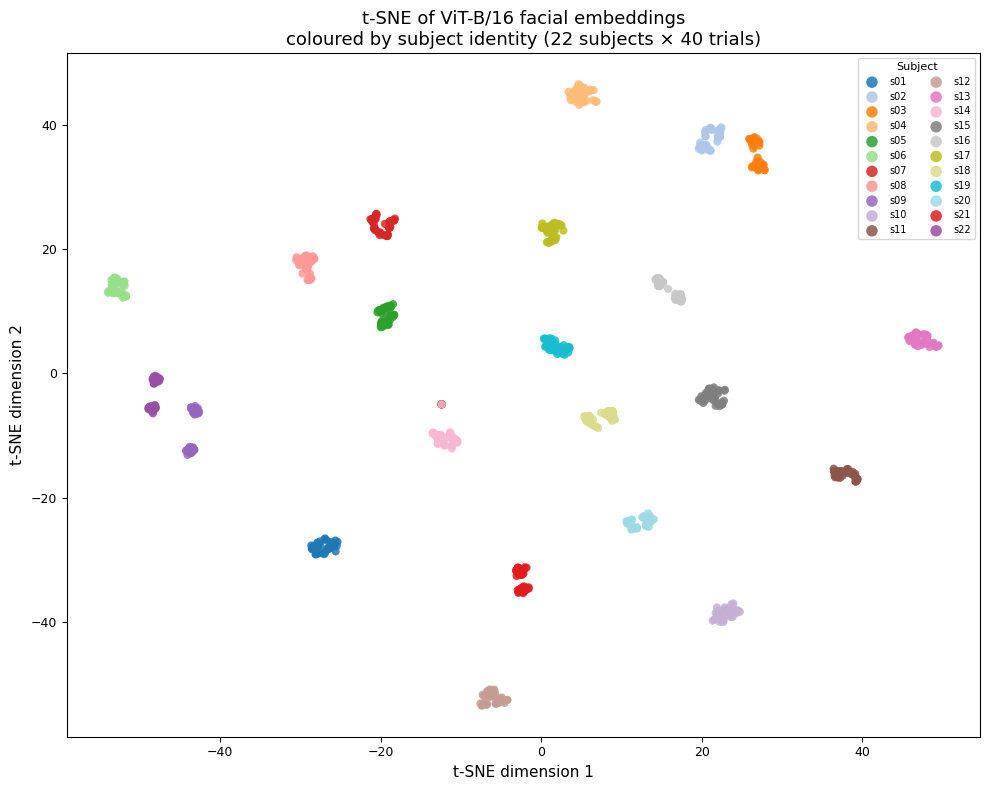

✔ Figure 1 saved — t-SNE by subject identity


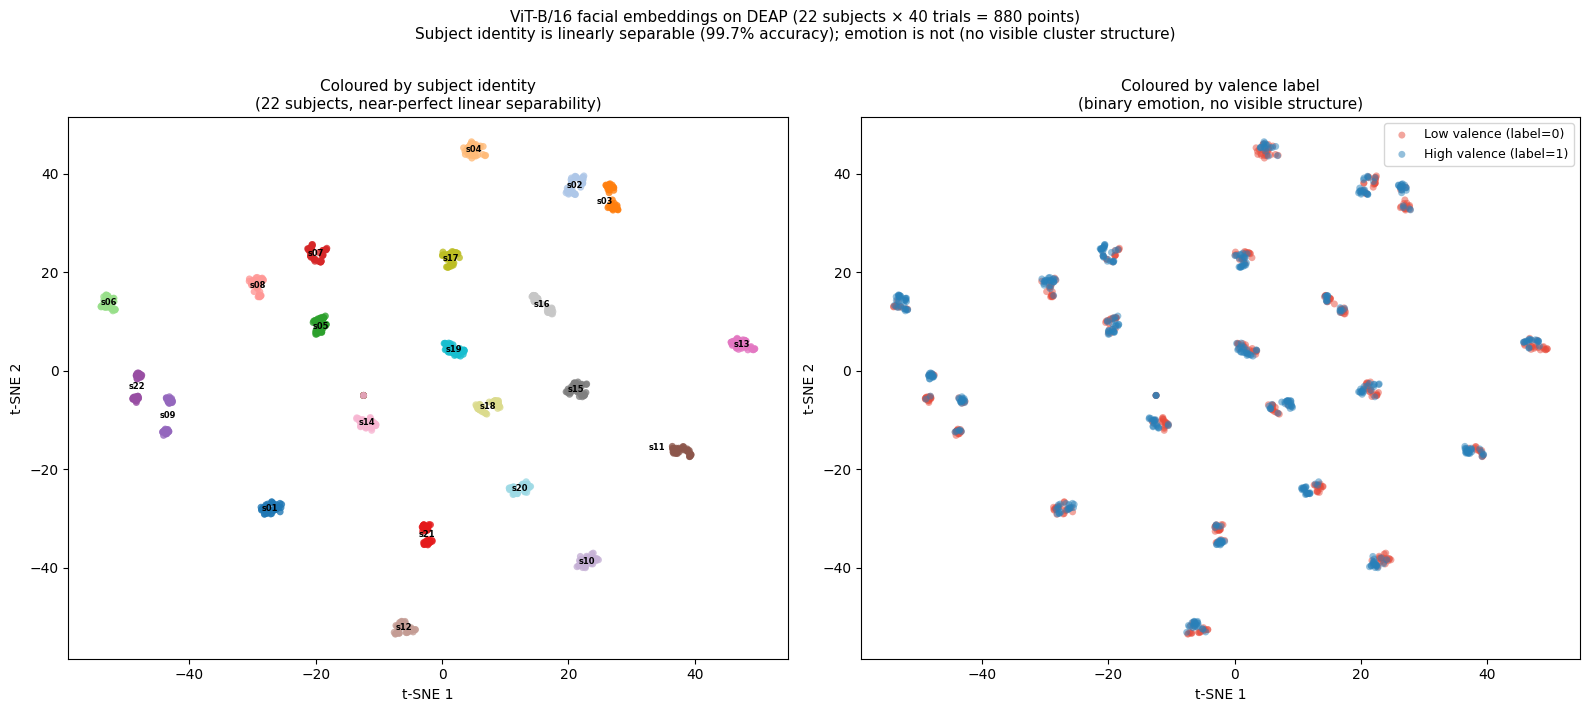

✔ Figure 2 saved — identity vs valence comparison


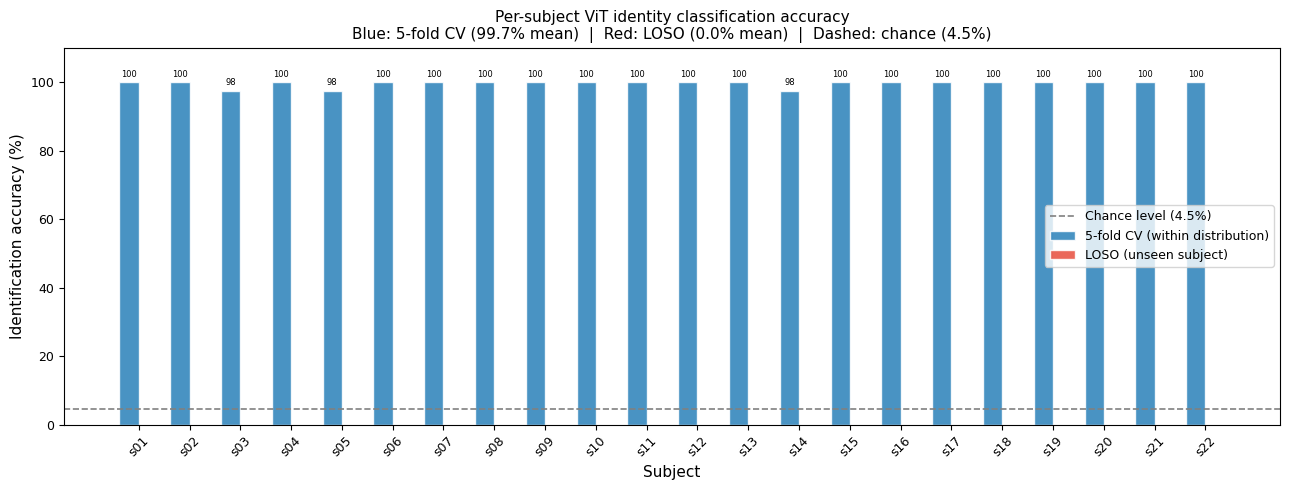

✔ Figure 3 saved — per-subject accuracy bar chart

LaTeX table for per-subject results:

\begin{table}[!ht]
\centering
\caption{Per-subject ViT-B/16 identity classification accuracy.
         Five-fold CV accuracy reflects within-distribution separability;
         LOSO accuracy reflects generalisation to unseen subjects.
         Chance level = 4.5\% (1 of 22 subjects).}
\label{tab:identity}
\footnotesize
\setlength{\tabcolsep}{4pt}
\begin{tabular}{lcc}
\toprule
Subject & 5-fold CV Acc (\%) & LOSO Acc (\%) \\
\midrule
s01 & 100.0 & 0.0 \\
s02 & 100.0 & 0.0 \\
s03 & 97.5 & 0.0 \\
s04 & 100.0 & 0.0 \\
s05 & 97.5 & 0.0 \\
s06 & 100.0 & 0.0 \\
s07 & 100.0 & 0.0 \\
s08 & 100.0 & 0.0 \\
s09 & 100.0 & 0.0 \\
s10 & 100.0 & 0.0 \\
s11 & 100.0 & 0.0 \\
s12 & 100.0 & 0.0 \\
s13 & 100.0 & 0.0 \\
s14 & 97.5 & 0.0 \\
s15 & 100.0 & 0.0 \\
s16 & 100.0 & 0.0 \\
s17 & 100.0 & 0.0 \\
s18 & 100.0 & 0.0 \\
s19 & 100.0 & 0.0 \\
s20 & 100.0 & 0.0 \\
s21 & 100.0 & 0.0 \\
s22 & 100.0 & 0.0 \\
\midrule
Mean & 

In [16]:
import os, json, torch
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from sklearn.manifold import TSNE
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# ── Assumes X (880,768) and y (880,) already loaded ───────────────────

FUSION_SUBJECTS = [f"s{i:02d}" for i in range(1, 23)]
os.makedirs("/kaggle/working/identity_figures", exist_ok=True)

scaler   = StandardScaler()
X_scaled = scaler.fit_transform(X)

# ─────────────────────────────────────────────────────────────────────
# FIGURE 1 — t-SNE coloured by subject identity
# ─────────────────────────────────────────────────────────────────────
print("Running t-SNE (2-3 min)...")
tsne   = TSNE(n_components=2, perplexity=30, n_iter=2000,
              random_state=42, n_jobs=-1)
X_tsne = tsne.fit_transform(X_scaled)
print("t-SNE done.")

colors22 = plt.cm.tab20(np.linspace(0, 1, 20)).tolist() + \
           plt.cm.Set1(np.linspace(0, 0.4, 2)).tolist()

fig, ax = plt.subplots(figsize=(10, 8))
for sid in range(22):
    mask = y == sid
    ax.scatter(X_tsne[mask, 0], X_tsne[mask, 1],
               c=[colors22[sid]], s=35, alpha=0.85,
               label=FUSION_SUBJECTS[sid], edgecolors='none')

ax.set_title("t-SNE of ViT-B/16 facial embeddings\n"
             "coloured by subject identity (22 subjects × 40 trials)",
             fontsize=13)
ax.set_xlabel("t-SNE dimension 1", fontsize=11)
ax.set_ylabel("t-SNE dimension 2", fontsize=11)
ax.legend(loc='upper right', fontsize=7, ncol=2,
          markerscale=1.4, framealpha=0.8,
          title="Subject", title_fontsize=8)
ax.tick_params(labelsize=9)
plt.tight_layout()
plt.savefig("/kaggle/working/identity_figures/tsne_identity.pdf",
            dpi=300, bbox_inches='tight')
plt.savefig("/kaggle/working/identity_figures/tsne_identity.png",
            dpi=300, bbox_inches='tight')
plt.show()
print("✔ Figure 1 saved — t-SNE by subject identity")

# ─────────────────────────────────────────────────────────────────────
# FIGURE 2 — side by side: identity vs emotion (valence label)
# ─────────────────────────────────────────────────────────────────────

# Extract valence labels from the .pt files
val_labels = []
BASE = "/kaggle/input/datasets/jarinproma/pgcn-deap-fusion-preprocessed/preprocessed_fusion"
for sid, subj in enumerate(FUSION_SUBJECTS):
    for trial_idx in range(40):
        win_path = f"{BASE}/{subj}/trial_{trial_idx:02d}/win_00.pt"
        if not os.path.exists(win_path):
            continue
        data = torch.load(win_path, map_location='cpu', weights_only=False)
        # y shape: (1, 5) → [val, aro, dom, lik, quad]
        label_val = int(data.y[0, 0].item())
        val_labels.append(label_val)

val_labels = np.array(val_labels)

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# Left: identity
ax = axes[0]
for sid in range(22):
    mask = y == sid
    ax.scatter(X_tsne[mask, 0], X_tsne[mask, 1],
               c=[colors22[sid]], s=25, alpha=0.8, edgecolors='none')
ax.set_title("Coloured by subject identity\n(22 subjects, near-perfect linear separability)",
             fontsize=11)
ax.set_xlabel("t-SNE 1", fontsize=10)
ax.set_ylabel("t-SNE 2", fontsize=10)

# Add subject labels at cluster centroids
for sid in range(22):
    mask = y == sid
    cx, cy = X_tsne[mask, 0].mean(), X_tsne[mask, 1].mean()
    ax.annotate(FUSION_SUBJECTS[sid], (cx, cy),
                fontsize=6, ha='center', va='center',
                color='black', fontweight='bold')

# Right: valence
ax2 = axes[1]
val_colors = {0: '#E74C3C', 1: '#2980B9'}
val_names  = {0: 'Low valence (label=0)', 1: 'High valence (label=1)'}
for vlab in [0, 1]:
    mask = val_labels == vlab
    ax2.scatter(X_tsne[mask, 0], X_tsne[mask, 1],
                c=val_colors[vlab], s=25, alpha=0.5,
                label=val_names[vlab], edgecolors='none')
ax2.set_title("Coloured by valence label\n(binary emotion, no visible structure)",
              fontsize=11)
ax2.set_xlabel("t-SNE 1", fontsize=10)
ax2.set_ylabel("t-SNE 2", fontsize=10)
ax2.legend(fontsize=9, framealpha=0.8)

plt.suptitle(
    "ViT-B/16 facial embeddings on DEAP (22 subjects × 40 trials = 880 points)\n"
    "Subject identity is linearly separable (99.7% accuracy); "
    "emotion is not (no visible cluster structure)",
    fontsize=11, y=1.01
)
plt.tight_layout()
plt.savefig("/kaggle/working/identity_figures/tsne_identity_vs_emotion.pdf",
            dpi=300, bbox_inches='tight')
plt.savefig("/kaggle/working/identity_figures/tsne_identity_vs_emotion.png",
            dpi=300, bbox_inches='tight')
plt.show()
print("✔ Figure 2 saved — identity vs valence comparison")

# ─────────────────────────────────────────────────────────────────────
# FIGURE 3 — Per-subject identification accuracy bar chart
# ─────────────────────────────────────────────────────────────────────

# Recompute per-subject LOSO accuracy (leave one subject out)
from sklearn.model_selection import LeaveOneGroupOut

logo         = LeaveOneGroupOut()
per_subj_acc = np.zeros(22)

for train_idx, test_idx in logo.split(X_scaled, y, groups=y):
    test_subj = y[test_idx[0]]
    clf_tmp   = LogisticRegression(max_iter=2000, C=1.0,
                                   random_state=42)
    clf_tmp.fit(X_scaled[train_idx], y[train_idx])
    acc = (clf_tmp.predict(X_scaled[test_idx]) == y[test_idx]).mean()
    per_subj_acc[test_subj] = acc

# 5-fold per-subject accuracy (within distribution)
from sklearn.model_selection import StratifiedKFold

clf_cv   = LogisticRegression(max_iter=2000, C=1.0, random_state=42)
cv       = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_preds = np.zeros(len(y))
for tr, te in cv.split(X_scaled, y):
    clf_cv.fit(X_scaled[tr], y[tr])
    cv_preds[te] = clf_cv.predict(X_scaled[te])

cv_per_subj = np.array([
    (cv_preds[y == sid] == sid).mean() for sid in range(22)
])

fig, ax = plt.subplots(figsize=(13, 5))
x       = np.arange(22)
width   = 0.38

bars1 = ax.bar(x - width/2, cv_per_subj * 100,  width,
               label='5-fold CV (within distribution)',
               color='#2980B9', alpha=0.85, edgecolor='white')
bars2 = ax.bar(x + width/2, per_subj_acc * 100, width,
               label='LOSO (unseen subject)',
               color='#E74C3C', alpha=0.85, edgecolor='white')

ax.axhline(100/22, color='gray', linestyle='--', linewidth=1.2,
           label=f'Chance level ({100/22:.1f}%)')
ax.set_xlabel("Subject", fontsize=11)
ax.set_ylabel("Identification accuracy (%)", fontsize=11)
ax.set_title(
    "Per-subject ViT identity classification accuracy\n"
    "Blue: 5-fold CV (99.7% mean)  |  Red: LOSO (0.0% mean)  |  "
    "Dashed: chance (4.5%)",
    fontsize=11
)
ax.set_xticks(x)
ax.set_xticklabels(FUSION_SUBJECTS, rotation=45, fontsize=8)
ax.set_ylim(0, 110)
ax.legend(fontsize=9, framealpha=0.8)
ax.tick_params(labelsize=9)

# Annotate CV bars with value
for bar in bars1:
    h = bar.get_height()
    if h > 0:
        ax.text(bar.get_x() + bar.get_width()/2, h + 1,
                f'{h:.0f}', ha='center', va='bottom', fontsize=6)

plt.tight_layout()
plt.savefig("/kaggle/working/identity_figures/per_subject_accuracy.pdf",
            dpi=300, bbox_inches='tight')
plt.savefig("/kaggle/working/identity_figures/per_subject_accuracy.png",
            dpi=300, bbox_inches='tight')
plt.show()
print("✔ Figure 3 saved — per-subject accuracy bar chart")

# ─────────────────────────────────────────────────────────────────────
# TABLE — LaTeX formatted per-subject results
# ─────────────────────────────────────────────────────────────────────
print("\nLaTeX table for per-subject results:\n")
print(r"\begin{table}[!ht]")
print(r"\centering")
print(r"\caption{Per-subject ViT-B/16 identity classification accuracy.")
print(r"         Five-fold CV accuracy reflects within-distribution separability;")
print(r"         LOSO accuracy reflects generalisation to unseen subjects.")
print(r"         Chance level = 4.5\% (1 of 22 subjects).}")
print(r"\label{tab:identity}")
print(r"\footnotesize")
print(r"\setlength{\tabcolsep}{4pt}")
print(r"\begin{tabular}{lcc}")
print(r"\toprule")
print(r"Subject & 5-fold CV Acc (\%) & LOSO Acc (\%) \\")
print(r"\midrule")
for sid in range(22):
    cv_a   = cv_per_subj[sid] * 100
    loso_a = per_subj_acc[sid] * 100
    print(f"{FUSION_SUBJECTS[sid]} & {cv_a:.1f} & {loso_a:.1f} \\\\")
print(r"\midrule")
print(f"Mean & {cv_per_subj.mean()*100:.1f} & {per_subj_acc.mean()*100:.1f} \\\\")
print(f"Std  & {cv_per_subj.std()*100:.1f}  & {per_subj_acc.std()*100:.1f}  \\\\")
print(r"\midrule")
print(r"\multicolumn{3}{l}{\footnotesize Chance level: 4.5\%.} \\")
print(r"\bottomrule")
print(r"\end{tabular}")
print(r"\end{table}")

# ─────────────────────────────────────────────────────────────────────
# Zip everything
# ─────────────────────────────────────────────────────────────────────
import shutil
shutil.make_archive("/kaggle/working/identity_figures",
                    "zip", "/kaggle/working", "identity_figures")
print(f"\n✔ All figures saved — download identity_figures.zip from output tab")

In [17]:
# Use valence label instead of subject identity
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
import numpy as np

scaler   = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Valence labels already loaded as val_labels
clf = LogisticRegression(max_iter=2000, C=1.0, random_state=42)
cv  = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
val_scores = cross_val_score(clf, X_scaled, val_labels, cv=cv,
                             scoring='accuracy')
print(f"Valence classification from ViT embeddings: "
      f"{val_scores.mean()*100:.1f}% ± {val_scores.std()*100:.1f}%")
print(f"Chance level: 50.0%")
print(f"Identity classification: 99.7%")

Valence classification from ViT embeddings: 69.0% ± 3.2%
Chance level: 50.0%
Identity classification: 99.7%
